**Question 1**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

PATH = "diagnosis.data"
FEATURE_COLS = ["temp", "nausea", "lumbar_pain", "urine_pushing", "micturition_pain", "urethra_burning"]
LABEL_COLS = ["bladder", "nephritis"]

In [3]:
df = pd.read_csv(PATH, sep="\t", decimal=",", header=None, encoding = "utf-16", names=FEATURE_COLS + LABEL_COLS)
yes_no_cols = FEATURE_COLS[1:] + LABEL_COLS
df[yes_no_cols] = df[yes_no_cols].eq("yes").astype(int)
df.head()

,temp,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_burning,bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


In [5]:
X = df[FEATURE_COLS]
y_powerset = df["bladder"].astype(str) + "_" + df["nephritis"].astype(str)
y_powerset.value_counts()

1_0    40
0_1    31
0_0    30
1_1    19
Name: count, dtype: int64

depth: 4 , leaves: 6 , train accuracy: 1.0


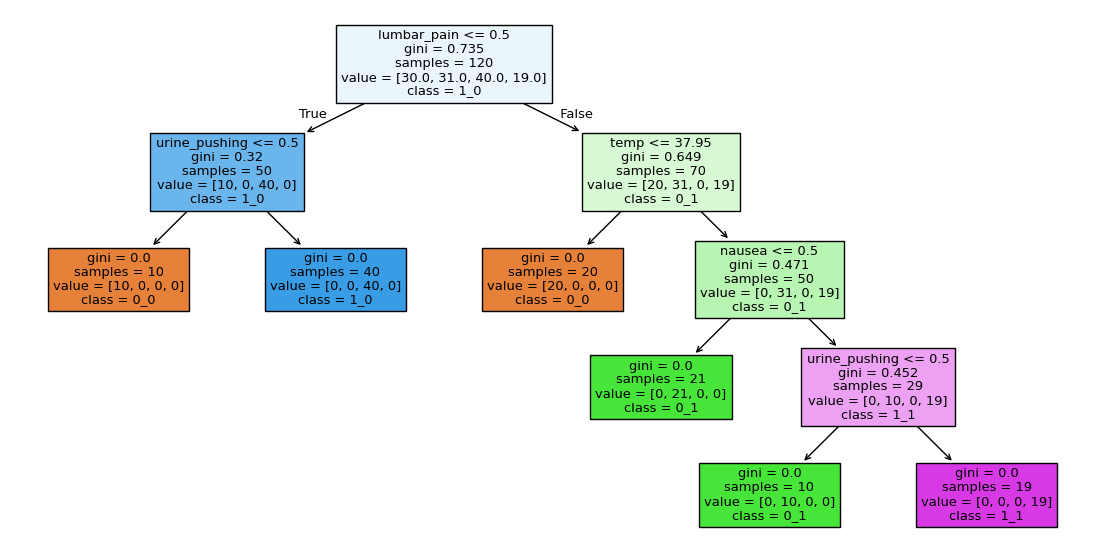

In [12]:
tree = DecisionTreeClassifier(random_state=42).fit(X, y_powerset)
print("depth:", tree.get_depth(), ", leaves:", tree.get_n_leaves(),", train accuracy:", tree.score(X, y_powerset))

plt.figure(figsize=(14, 7))
plot_tree(tree, feature_names=FEATURE_COLS, class_names=tree.classes_, filled=True)
plt.show()

In [17]:
def tree_rules(tree, feature_names):
    t = tree.tree_
    rules = []
    def recurse(node, conditions):
        if t.children_left[node] == -1:
            label = tree.classes_[t.value[node].argmax()]
            rules.append(f"IF {' AND '.join(conditions)} THEN {label}  (n={t.n_node_samples[node]})")
            return
        name, threshold = feature_names[t.feature[node]], t.threshold[node]
        recurse(t.children_left[node], conditions + [f"{name} <= {threshold:.2f}"])
        recurse(t.children_right[node], conditions + [f"{name} > {threshold:.2f}"])

    recurse(0, [])
    return rules

full_rules = tree_rules(tree, FEATURE_COLS)
for rule in full_rules:
    print(rule)


IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN 0_0  (n=10)
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN 1_0  (n=40)
IF lumbar_pain > 0.50 AND temp <= 37.95 THEN 0_0  (n=20)
IF lumbar_pain > 0.50 AND temp > 37.95 AND nausea <= 0.50 THEN 0_1  (n=21)
IF lumbar_pain > 0.50 AND temp > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN 0_1  (n=10)
IF lumbar_pain > 0.50 AND temp > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN 1_1  (n=19)


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_folds = 5
cv_splitter = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)

pruning_path = tree.cost_complexity_pruning_path(X, y_powerset)
pruning_path.ccp_alphas

array([0.        , 0.09816667, 0.13333333, 0.182     , 0.22291667])

In [19]:
pruning_results = []
for alpha in pruning_path.ccp_alphas:
    pruned_tree = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha).fit(X, y_powerset)
    cv_accuracy = cross_val_score(DecisionTreeClassifier(random_state=42, ccp_alpha=alpha),
                                  X, y_powerset, cv=cv_splitter).mean()
    pruning_results.append({"alpha": alpha, "leaves": pruned_tree.get_n_leaves(),
                            "train_acc": pruned_tree.score(X, y_powerset), "cv_acc": cv_accuracy})
pruning_df = pd.DataFrame(pruning_results).round(3)
pruning_df

,alpha,leaves,train_acc,cv_acc
0,0.000,6,1.000,0.992
1,0.098,4,0.842,0.858
2,0.133,3,0.758,0.758
3,0.182,2,0.592,0.667
4,0.223,1,0.333,0.483


In [ ]:
ACCURACY_TOLERANCE = 0.01
best_cv_acc = pruning_df["cv_acc"].max()
chosen_alpha = pruning_df.loc[pruning_df["cv_acc"] >= best_cv_acc - ACCURACY_TOLERANCE, "alpha"].max()

minimal_tree = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=chosen_alpha).fit(X, y_powerset)
print("chosen alpha:", chosen_alpha, "| leaves:", minimal_tree.get_n_leaves())
for rule in tree_rules(minimal_tree, FEATURE_COLS):
    print(rule)


chosen alpha: 0.0 | leaves: 6
IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN 0_0  (n=10)
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN 1_0  (n=40)
IF lumbar_pain > 0.50 AND temp <= 37.95 THEN 0_0  (n=20)
IF lumbar_pain > 0.50 AND temp > 37.95 AND nausea <= 0.50 THEN 0_1  (n=21)
IF lumbar_pain > 0.50 AND temp > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN 0_1  (n=10)
IF lumbar_pain > 0.50 AND temp > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN 1_1  (n=19)
